# 03 · Embeddings to a held-out classification map

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute. Download: 0 bytes. Source: San Francisco Bay
Area, 6,336 official 1280 m AEF **2021** overview cells and ESA WorldCover
**2021 v200** grouped dominant labels (both CC-BY-4.0; see bundled provenance).
Reference labels aggregate native 10 m pixel centers inside each AEF polygon.
This is a software teaching example, **not reproduction of the current global
paper benchmark**. It does not add any model to the frozen 20-system study.

The split was fixed before evaluation: two spatial folds by grid column.
A model fitted only on the west half (columns 0–32) predicts the east half
(columns 39–71), and a model fitted only on the east half predicts the west.
Six buffer columns (7.68 km) are never fitted or scored, so every scored cell
has an out-of-fold prediction: 5,806 scored cells, 528 buffer cells, two bare
cells not scored. The four classes are built, vegetation, cropland and water.
Cropland is concentrated in the east (512 vs 51 cells); the imbalance is retained,
not resampled. No parameter selection or test-label tuning:
StandardScaler + LogisticRegression(C=1, class_weight="balanced", tol=1e-8, seed=42).
Training uses float64 and a strict convergence tolerance for numerical reproducibility.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")
import json
from earth_embedding.demo import classify_demo, plot_classification

CPU demo; outputs are saved in ./outputs


In [2]:
bayarea = load_demo("bayarea")
result = classify_demo(bayarea)
display(__import__("pandas").crosstab(result["samples"].demo_split, result["samples"].class_name))
print(json.dumps(result["metrics"], indent=2))

class_name,bare,built,cropland,vegetation,water
demo_split,,,,,
buffer,0,158,1,299,70
east,0,325,512,1936,131
west,2,504,51,1433,914


{
  "scope": "San Francisco Bay Area regional software demonstration; not a paper benchmark reproduction",
  "seed": 42,
  "estimator": {
    "name": "StandardScaler + LogisticRegression",
    "C": 1.0,
    "class_weight": "balanced",
    "tol": 1e-08,
    "max_iter": 4000,
    "dtype": "float64",
    "solver": "lbfgs"
  },
  "model": "AEF 2021 official 1280m overview features",
  "total": 6336,
  "scored": 5806,
  "split_counts": {
    "west": 2904,
    "east": 2904,
    "buffer": 528
  },
  "class_counts": {
    "buffer": {
      "bare": 0,
      "built": 158,
      "cropland": 1,
      "vegetation": 299,
      "water": 70
    },
    "east": {
      "bare": 0,
      "built": 325,
      "cropland": 512,
      "vegetation": 1936,
      "water": 131
    },
    "west": {
      "bare": 2,
      "built": 504,
      "cropland": 51,
      "vegetation": 1433,
      "water": 914
    }
  },
  "split": "Two spatial folds: west columns 0-32 and east columns 39-71 each predicted by a model fitted 

In [3]:
samples = result["samples"]
for fit_on, predict in [("west", "east"), ("east", "west")]:
    train = samples.demo_split.eq(fit_on).to_numpy() & samples.class_name.ne("bare").to_numpy()
    scaler = result["estimators"][f"{fit_on}_to_{predict}"].named_steps["standardscaler"]
    np.testing.assert_allclose(scaler.mean_, bayarea.features[train].mean(axis=0, dtype=np.float64))
    assert samples.loc[samples.demo_split.eq(predict) & samples.prediction.notna(), "predicted_by"].eq(f"fit_{fit_on}").all()
assert samples.loc[samples.demo_split.eq("buffer"), "prediction"].isna().all()
print("Each scaler was fitted on its own half only; every scored cell is out of fold.")

Each scaler was fitted on its own half only; every scored cell is out of fold.


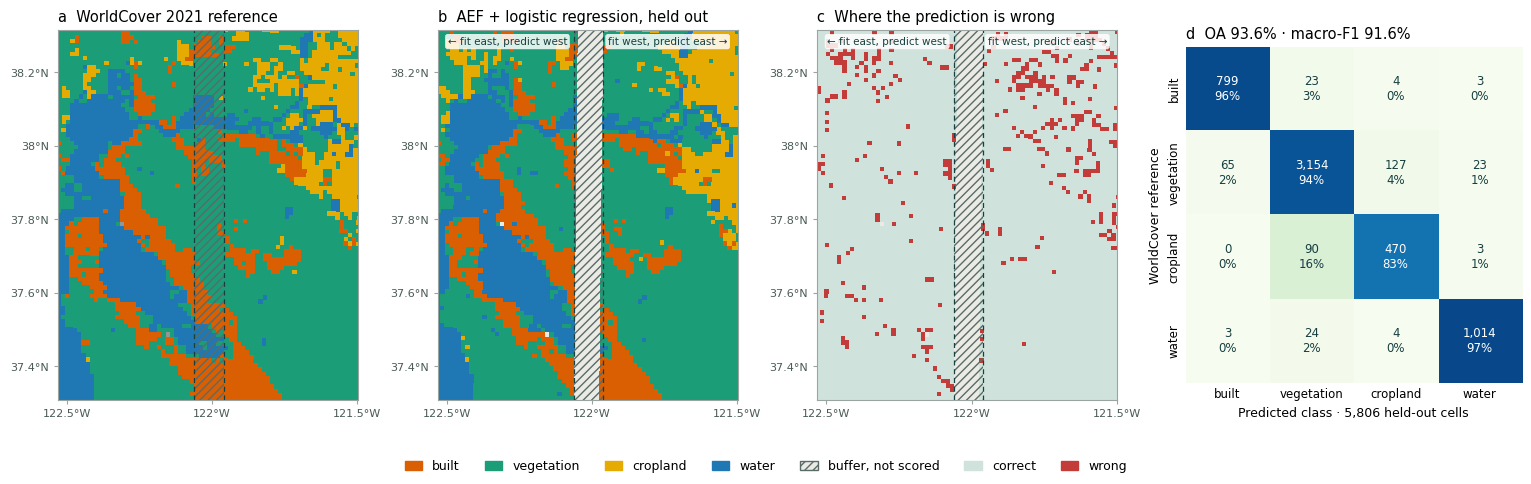

In [4]:
fig = plot_classification(result)
fig.savefig(out / "bayarea-classification.png", dpi=160)
result["samples"].to_csv(out / "predictions.csv", index=False)
(out / "metrics.json").write_text(json.dumps(result["metrics"], indent=2))
plt.show()

The hatched buffer is neither fitted nor scored. Red errors and confusion-matrix
rows compare predictions to WorldCover reference labels, not field-survey truth.
OA is overall accuracy; Macro-F1 gives each of the four classes equal weight;
Balanced Accuracy is mean per-class recall. Two regional folds give no uncertainty
estimate or global generalization claim. Same-year input and reference products
may share satellite signals; the buffer reduces immediate adjacency leakage,
but does not remove all spatial autocorrelation.